# 02 · Segmentación de clientes con K‑Means (RFM)

**Objetivo:** agrupar a los **clientes individuales** de AdventureWorks en segmentos homogéneos según su comportamiento de compra para diseñar acciones comerciales diferenciadas.

**Variables (modelo RFM):**
- **Recency** — días desde la última compra (menor = mejor)
- **Frequency** — número de pedidos
- **Monetary** — gasto total (SubTotal, USD)

**Alcance:** 18.484 clientes individuales (B2C). Las tiendas (B2B) se excluyen porque, como vimos en el EDA, tienen una escala de compra ~20× mayor y dominarían los clusters.

**Pasos:** 1) preparación (log + estandarización) → 2) elección de *k* → 3) entrenamiento → 4) validación → 5) interpretación y perfilado → 6) recomendaciones.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from src.features import load_raw, build_customer_features
from src.viz import set_style, PALETTE, SEQ, MUTED

set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 50)
from src.clustering import RFM_COLS, prepare_matrix, evaluate_k, fit_kmeans, pca_2d, name_segments
from src.viz import SEGMENT_COLORS, SEGMENT_MARKERS, segment_order
from sklearn.metrics import silhouette_samples

## 1. Datos de entrada

In [2]:
orders, details, demo, _ = load_raw()
feats = build_customer_features(orders, details, demo)
print(f"{len(feats):,} clientes individuales")
feats[RFM_COLS].describe().T

18,484 clientes individuales


,count,mean,std,min,25%,50%,75%,max
Recency,"18,484.00",190.33,146.29,1.00,87.00,169.00,264.00,"1,127.00"
Frequency,"18,484.00",1.50,1.10,1.00,1.00,1.00,2.00,28.00
Monetary,"18,484.00","1,588.33","2,124.23",2.29,49.97,270.26,"2,511.28","13,295.38"


## 2. Preparación de las variables

K‑Means usa distancia euclidiana, así que es sensible a **escala** y a **valores extremos**:

1. `log1p` reduce la asimetría de Frequency y Monetary.
2. `StandardScaler` deja cada variable con media 0 y desviación 1 para que todas pesen igual.

In [3]:
X, scaler = prepare_matrix(feats)
comp = pd.DataFrame({"skew original": feats[RFM_COLS].skew(),
                     "skew log1p": np.log1p(feats[RFM_COLS]).skew()})
comp

,skew original,skew log1p
Recency,2.46,-1.13
Frequency,12.58,1.94
Monetary,1.41,-0.09


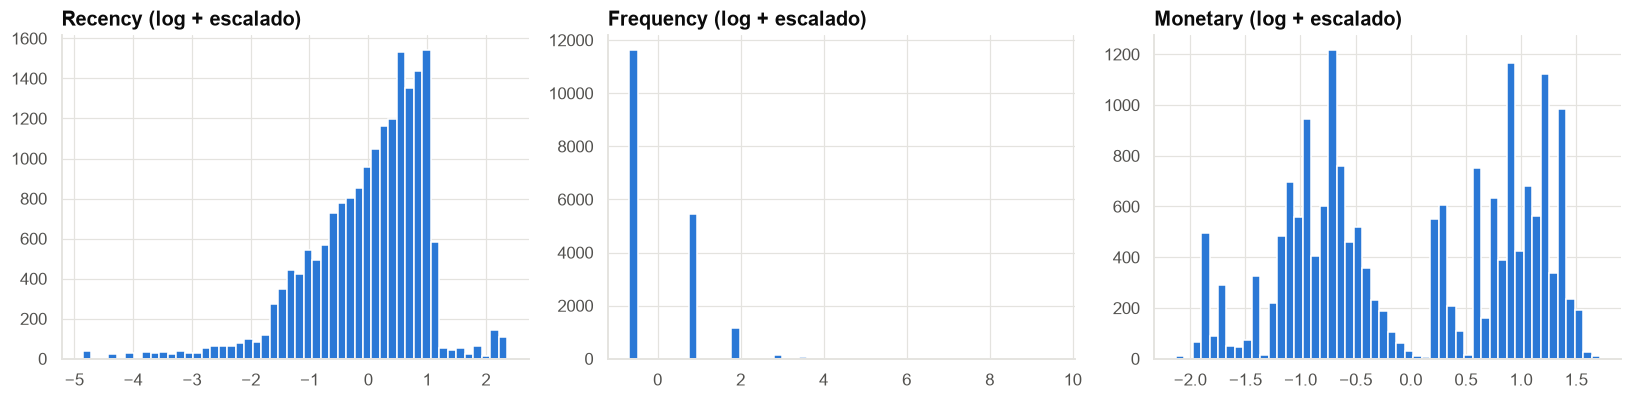

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (ax, col) in enumerate(zip(axes, RFM_COLS)):
    ax.hist(X[:, i], bins=50, color=PALETTE[0]); ax.set_title(f"{col} (log + escalado)")
plt.tight_layout(); plt.show()

## 3. Elección del número de clusters *k*

Usamos cuatro criterios complementarios:

| Métrica | Mejor si… |
|---|---|
| Inercia (método del codo) | se observa un "codo" |
| Silhouette | más alto (−1 a 1) |
| Calinski‑Harabasz | más alto |
| Davies‑Bouldin | más bajo |

In [5]:
scores = evaluate_k(X, range(2, 11))
scores.set_index("k")

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,"34,809.77",0.41,"10,959.84",1.07
3,"25,726.81",0.39,"10,676.66",1.07
4,"19,807.01",0.41,"11,085.66",0.89
5,"16,924.29",0.44,"10,516.74",0.98
6,"14,688.05",0.45,"10,256.50",0.91
7,"12,469.19",0.46,"10,615.47",0.87
8,"10,711.13",0.46,"11,025.02",0.77
9,"8,967.45",0.44,"11,971.15",0.77
10,"8,017.18",0.45,"12,146.46",0.78


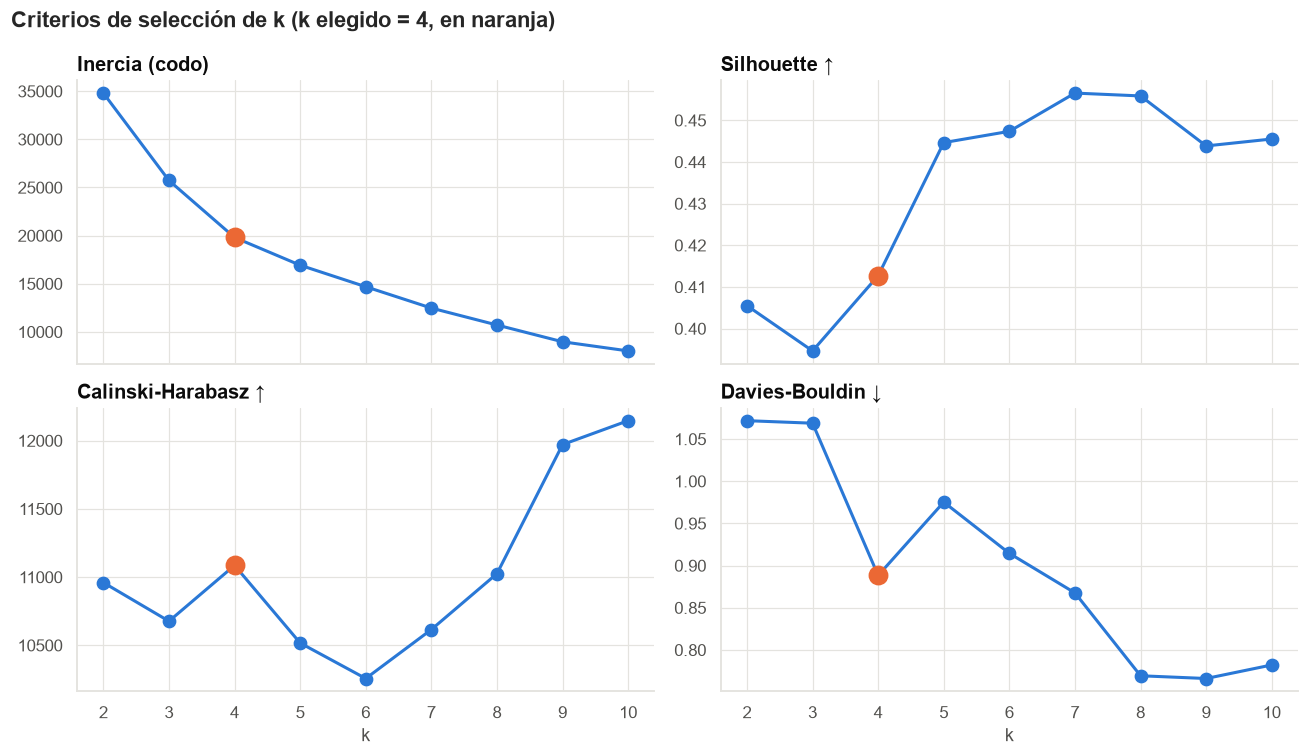

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
specs = [("inertia", "Inercia (codo)"), ("silhouette", "Silhouette ↑"),
         ("calinski_harabasz", "Calinski-Harabasz ↑"), ("davies_bouldin", "Davies-Bouldin ↓")]
K_SEL = 4
for ax, (col, title) in zip(axes.flat, specs):
    ax.plot(scores["k"], scores[col], color=PALETTE[0], marker="o", markersize=8)
    sel = scores.set_index("k").loc[K_SEL, col]
    ax.plot([K_SEL], [sel], marker="o", markersize=12, color=PALETTE[1], zorder=3)
    ax.set_title(title); ax.set_xticks(scores["k"])
axes[1, 0].set_xlabel("k"); axes[1, 1].set_xlabel("k")
plt.suptitle(f"Criterios de selección de k (k elegido = {K_SEL}, en naranja)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Decisión: k = 4.**

- En la curva de inercia la mayor ganancia marginal se agota alrededor de k = 4.
- Davies‑Bouldin tiene una caída clara en k = 4 y Calinski‑Harabasz un máximo local.
- Silhouette sigue subiendo levemente después, pero valores de k mayores parten segmentos en subgrupos casi idénticos, que no aportan una acción comercial distinta.
- Cuatro segmentos son **interpretables y accionables** para el negocio.

## 4. Entrenamiento del modelo final

In [7]:
model = fit_kmeans(X, K_SEL)
feats["Cluster"] = model.labels_
names = name_segments(feats)
feats["Segment"] = feats["Cluster"].map(names)
ORDER = segment_order(feats["Segment"])

size = feats["Segment"].value_counts().reindex(ORDER).to_frame("clientes")
size["%"] = 100 * size["clientes"] / size["clientes"].sum()
size

,clientes,%
Segment,,
Campeones,5591,30.25
Alto valor en riesgo,3664,19.82
Nuevos,2641,14.29
Bajo valor inactivos,6588,35.64


In [8]:
centers = pd.DataFrame(np.expm1(scaler.inverse_transform(model.cluster_centers_)),
                       columns=RFM_COLS).rename(index=names).loc[ORDER]
centers.round(1).rename_axis("Centroide (escala original)")

,Recency,Frequency,Monetary
Centroide (escala original),,,
Campeones,138.50,2.30,"2,935.70"
Alto valor en riesgo,216.30,1.00,"1,312.20"
Nuevos,32.50,1.30,90.50
Bajo valor inactivos,200.50,1.10,38.20


## 5. Validación: coeficiente Silhouette por cluster

Silhouette medio global: 0.411


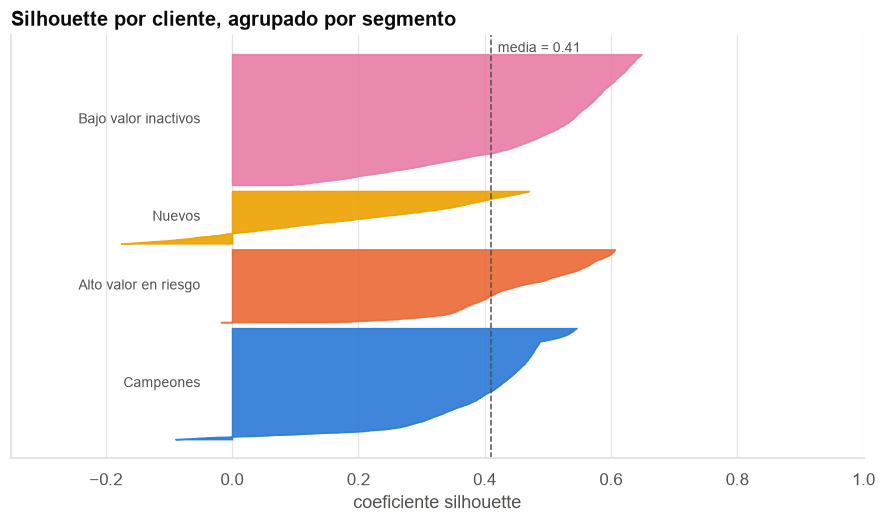

In [9]:
sil = silhouette_samples(X, feats["Cluster"])
feats["Silhouette"] = sil
print(f"Silhouette medio global: {sil.mean():.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
y0 = 0
for seg in ORDER:
    v = np.sort(feats.loc[feats.Segment == seg, "Silhouette"].values)
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=SEGMENT_COLORS[seg], alpha=0.9)
    ax.text(-0.05, y0 + len(v) / 2, seg, ha="right", va="center", color=MUTED, fontsize=9)
    y0 += len(v) + 300
ax.axvline(sil.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.text(sil.mean() + 0.01, y0 - 200, f"media = {sil.mean():.2f}", color=MUTED, fontsize=9)
ax.set_yticks([]); ax.set_xlabel("coeficiente silhouette"); ax.set_xlim(-0.35, 1)
ax.set_title("Silhouette por cliente, agrupado por segmento")
plt.show()

## 6. Visualización de los clusters

### 6.1 Proyección PCA en 2D

Varianza explicada: [50.2 35.4] % — total 85.7%


,Recency,Frequency,Monetary
PC1,-0.15,0.72,0.68
PC2,0.93,-0.13,0.34


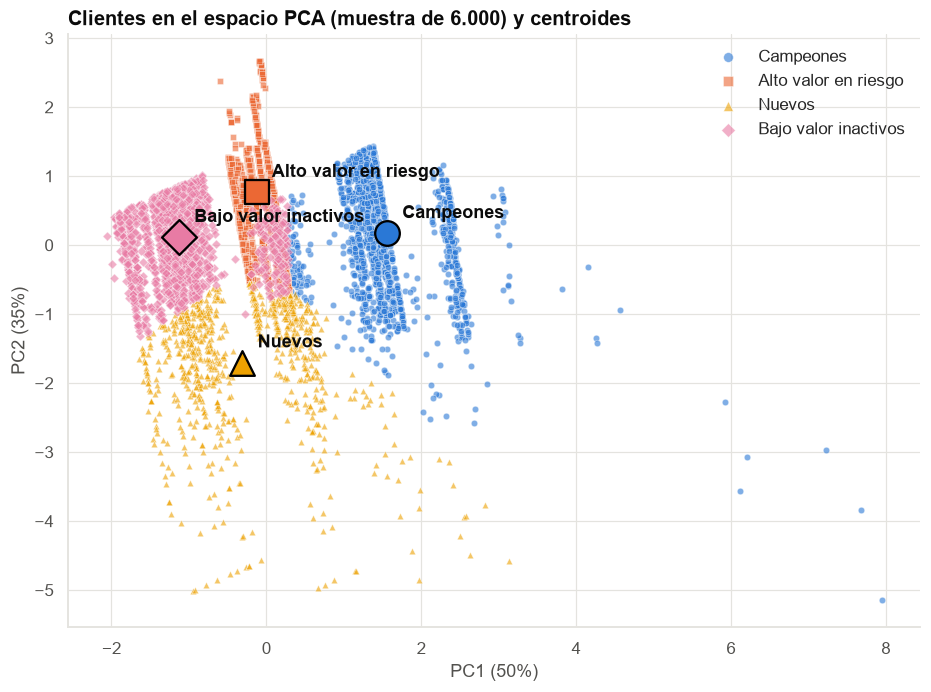

In [10]:
coords, pca = pca_2d(X)
feats["PC1"], feats["PC2"] = coords[:, 0], coords[:, 1]
print("Varianza explicada:", (pca.explained_variance_ratio_ * 100).round(1), "% — total",
      f"{pca.explained_variance_ratio_.sum():.1%}")
display(pd.DataFrame(pca.components_, columns=RFM_COLS, index=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(figsize=(10, 7))
sample = feats.sample(6000, random_state=42)
for seg in ORDER:
    s = sample[sample.Segment == seg]
    ax.scatter(s.PC1, s.PC2, s=18, alpha=0.6, color=SEGMENT_COLORS[seg], marker=SEGMENT_MARKERS[seg],
               edgecolors="white", linewidths=0.4, label=seg)
c2 = pca.transform(model.cluster_centers_)
for i, (x, y) in enumerate(c2):
    ax.scatter(x, y, s=260, color=SEGMENT_COLORS[names[i]], marker=SEGMENT_MARKERS[names[i]],
               edgecolors="black", linewidths=1.5, zorder=3)
    ax.annotate(names[i], (x, y), xytext=(10, 10), textcoords="offset points", fontweight="bold", color="#0b0b0b")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Clientes en el espacio PCA (muestra de 6.000) y centroides")
ax.legend(loc="best", markerscale=1.5)
plt.show()

### 6.2 Recency vs Monetary (escala original)

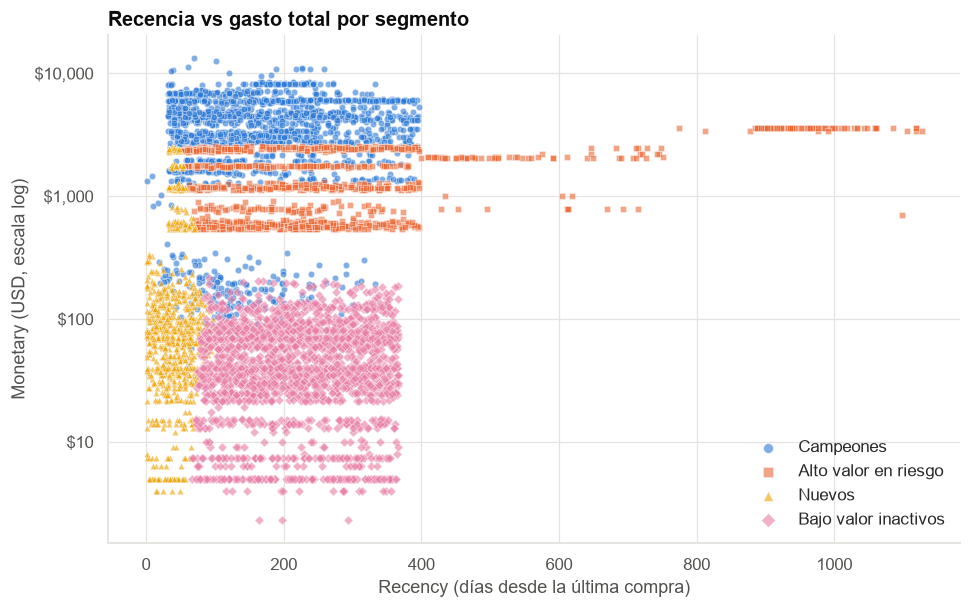

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
for seg in ORDER:
    s = sample[sample.Segment == seg]
    ax.scatter(s.Recency, s.Monetary, s=18, alpha=0.6, color=SEGMENT_COLORS[seg],
               marker=SEGMENT_MARKERS[seg], edgecolors="white", linewidths=0.4, label=seg)
ax.set_yscale("log"); ax.set_xlabel("Recency (días desde la última compra)"); ax.set_ylabel("Monetary (USD, escala log)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set_title("Recencia vs gasto total por segmento"); ax.legend(markerscale=1.5)
plt.show()

## 7. Perfil de cada segmento

### 7.1 Comportamiento de compra

In [12]:
profile = feats.groupby("Segment").agg(
    Clientes=("CustomerID", "count"),
    Recency_dias=("Recency", "median"),
    Frecuencia=("Frequency", "mean"),
    Gasto_total=("Monetary", "mean"),
    Ticket_prom=("AvgTicket", "mean"),
    Antiguedad_dias=("Tenure", "median"),
    Ventas_totales=("Monetary", "sum"),
).loc[ORDER]
profile["% clientes"] = 100 * profile.Clientes / profile.Clientes.sum()
profile["% ventas"] = 100 * profile.Ventas_totales / profile.Ventas_totales.sum()
profile.round(1)

,Clientes,Recency_dias,Frecuencia,Gasto_total,Ticket_prom,Antiguedad_dias,Ventas_totales,% clientes,% ventas
Segment,,,,,,,,,
Campeones,5591,155.00,2.40,"4,021.60","1,797.00",645.00,"22,484,809.10",30.20,76.60
Alto valor en riesgo,3664,225.50,1.00,"1,574.50","1,574.50",225.50,"5,768,872.00",19.80,19.60
Nuevos,2641,41.00,1.30,288.90,271.80,51.00,"762,902.20",14.30,2.60
Bajo valor inactivos,6588,216.00,1.10,51.90,48.70,228.00,"342,094.00",35.60,1.20


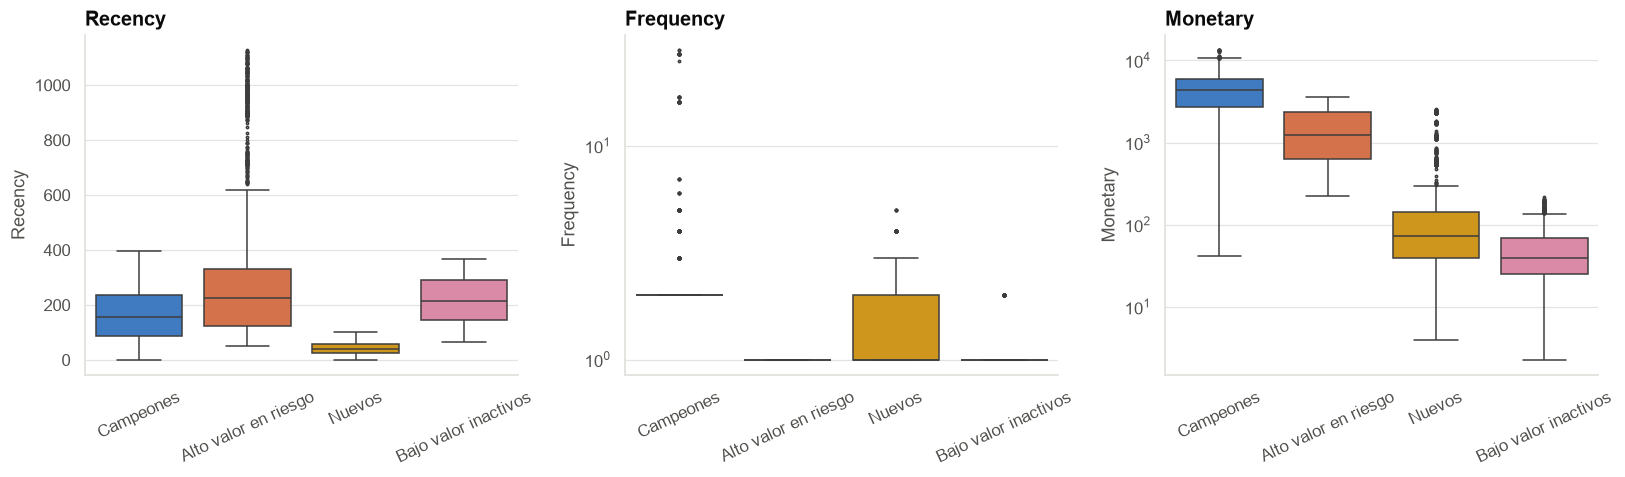

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, log in zip(axes, RFM_COLS, [False, True, True]):
    sns.boxplot(data=feats, x="Segment", y=col, order=ORDER, hue="Segment", palette=SEGMENT_COLORS,
                legend=False, ax=ax, fliersize=1.5, linewidth=1)
    if log: ax.set_yscale("log")
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

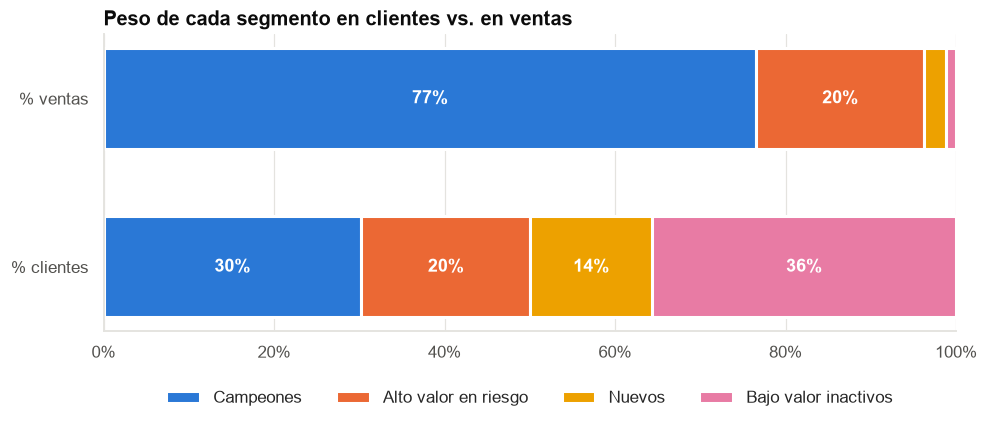

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.5))
share = profile[["% clientes", "% ventas"]].T
left = np.zeros(2)
for seg in ORDER:
    ax.barh(share.index, share[seg], left=left, color=SEGMENT_COLORS[seg], label=seg, edgecolor="white", linewidth=2, height=0.6)
    for y, (l, v) in enumerate(zip(left, share[seg])):
        if v > 6: ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += share[seg].values
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Peso de cada segmento en clientes vs. en ventas")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15)); ax.grid(axis="y", visible=False)
plt.show()

### 7.2 ¿Qué compran?

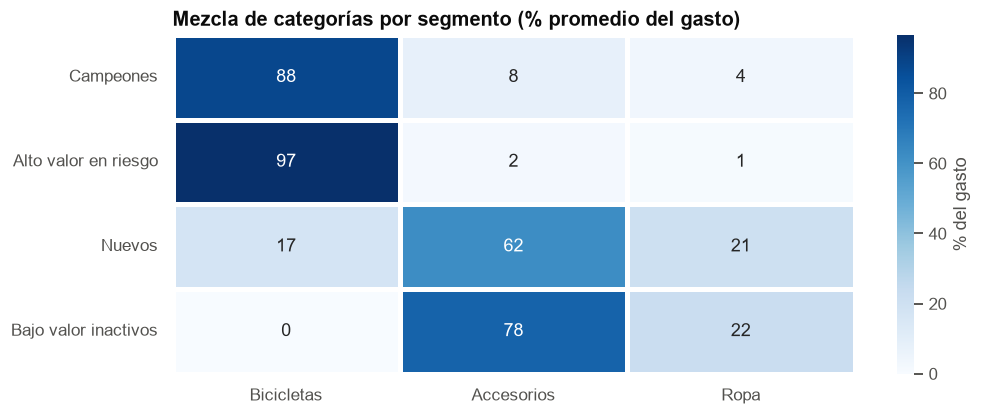

In [15]:
mix = feats.groupby("Segment")[["Share_Bikes", "Share_Accessories", "Share_Clothing"]].mean().loc[ORDER] * 100
mix.columns = ["Bicicletas", "Accesorios", "Ropa"]
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(mix, annot=True, fmt=".0f", cmap=SEQ, linewidths=2, linecolor="white", cbar_kws={"label": "% del gasto"}, ax=ax)
ax.set_title("Mezcla de categorías por segmento (% promedio del gasto)"); ax.set_ylabel("")
plt.show()

### 7.3 ¿Quiénes son? (demografía y territorio)

In [16]:
demo_prof = feats.groupby("Segment").agg(
    Edad=("Age", "median"),
    Hijos=("TotalChildren", "mean"),
    Autos=("NumberCarsOwned", "mean"),
    Propietario_vivienda=("HomeOwnerFlag", "mean"),
    Casados=("MaritalStatus", lambda s: (s == "M").mean()),
    Mujeres=("Gender", lambda s: (s == "F").mean()),
).loc[ORDER]
demo_prof[["Propietario_vivienda", "Casados", "Mujeres"]] *= 100
demo_prof.round(1)

,Edad,Hijos,Autos,Propietario_vivienda,Casados,Mujeres
Segment,,,,,,
Campeones,50.00,1.60,1.40,70.40,51.90,50.20
Alto valor en riesgo,49.00,1.70,1.10,65.40,51.60,50.70
Nuevos,51.00,2.00,1.60,66.70,55.30,49.20
Bajo valor inactivos,52.00,2.00,1.70,66.90,57.00,48.10


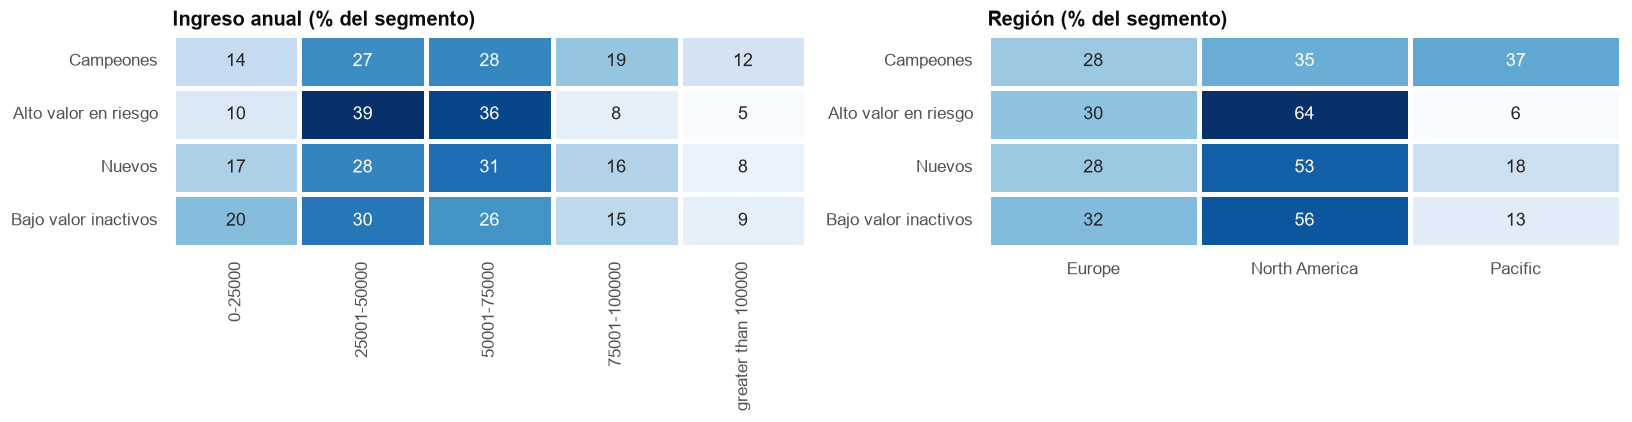

In [17]:
inc = pd.crosstab(feats.Segment, feats.YearlyIncome, normalize="index").loc[ORDER] * 100
terr = pd.crosstab(feats.Segment, feats.TerritoryGroup, normalize="index").loc[ORDER] * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(inc, annot=True, fmt=".0f", cmap=SEQ, linewidths=2, linecolor="white", ax=axes[0], cbar=False)
axes[0].set_title("Ingreso anual (% del segmento)"); axes[0].set_ylabel(""); axes[0].set_xlabel("")
sns.heatmap(terr, annot=True, fmt=".0f", cmap=SEQ, linewidths=2, linecolor="white", ax=axes[1], cbar=False)
axes[1].set_title("Región (% del segmento)"); axes[1].set_ylabel(""); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 8. Interpretación y recomendaciones de negocio

| Segmento | % clientes | % ventas | Perfil (valores típicos) | Qué compra | Acción recomendada |
|---|---|---|---|---|---|
| **Campeones** | 30 % | **77 %** | ~2,4 pedidos, gasto medio ≈ $4.000, clientes desde 2011‑2012 | 88 % bicicletas | Programa de fidelización / VIP, acceso anticipado a modelos nuevos, venta cruzada de componentes y accesorios premium |
| **Alto valor en riesgo** | 20 % | 20 % | 1 solo pedido de ≈ $1.575 hace ~7 meses | 97 % bicicletas | Reactivación: mantenimiento de la bici, accesorios compatibles, cupón para una segunda compra. **Hay que actuar antes de perderlos** |
| **Nuevos** | 14 % | 3 % | Compraron hace ~1 mes, ticket ≈ $270 | 62 % accesorios, 17 % bicicletas | Onboarding: email de bienvenida y recomendaciones para convertir en compradores de bicicleta |
| **Bajo valor inactivos** | 36 % | 1 % | 1 pedido de ≈ $50 hace ~7 meses | 100 % accesorios y ropa (clientes de la ola 2013‑T3) | Campañas masivas de bajo costo (email automatizado); no invertir presupuesto de vendedores |

**Observaciones del modelo**

- **Concentración (tipo Pareto):** el 30 % de los clientes (Campeones) genera el 77 % de las ventas B2C.
- **Calidad de la segmentación:** silhouette medio = 0,41 (estructura razonable). "Nuevos" es el grupo menos compacto (≈ 0,20) porque es un segmento de *transición*: con el tiempo sus clientes migrarán a Campeones o a Inactivos.
- **La demografía casi no discrimina:** edad, género y estado civil son muy parecidos entre segmentos; lo que separa a los clientes es su **comportamiento**, no su perfil. La excepción es el ingreso: los Campeones tienen mayor proporción de ingresos altos, y los Inactivos de ingresos < $25.000.
- **Territorio:** los Campeones se concentran en **Pacific (Australia)** (37 % vs 6‑18 % en los otros segmentos) → mercado clave para bicicletas.

**Limitaciones**

- Recency está medida respecto al 01/07/2014 (fin del dataset), no respecto a hoy.
- K‑Means asume clusters esféricos y de tamaño similar; se podría comparar con DBSCAN o clustering jerárquico.
- El margen usa el costo estándar actual, no el histórico.

## 9. Guardar resultados

In [18]:
out = ROOT / "data" / "processed"
feats.to_parquet(out / "customer_segments.parquet", index=False)
feats[["CustomerID", "Segment", "Cluster", "Recency", "Frequency", "Monetary", "AvgTicket"]].to_csv(
    ROOT / "reports" / "clientes_segmentados.csv", index=False)
profile.round(2).to_csv(ROOT / "reports" / "perfil_segmentos.csv")
print("Guardado: data/processed/customer_segments.parquet, reports/clientes_segmentados.csv, reports/perfil_segmentos.csv")

Guardado: data/processed/customer_segments.parquet, reports/clientes_segmentados.csv, reports/perfil_segmentos.csv
